# Problem 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

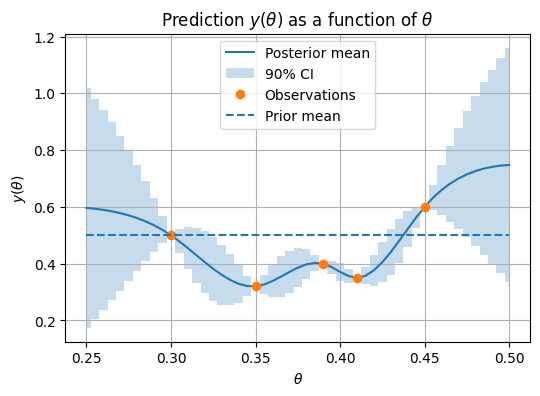

In [2]:
# a)
# observations
theta_obs = np.array([0.30,0.35,0.39,0.41,0.45])
y_obs = np.array([0.50,0.32,0.40,0.35,0.60])

# prior
mu = 0.5 # mean  
var = 0.25 # variance

def cov(t1, t2):
    d = np.abs(t1[:,None] - t2[None,:])
    return var * (1 + 15*d) * np.exp(-15*d)

# grid 
theta_grid = np.arange(0.25, 0.5001, 0.005) # to include endpoint

covAA = cov(theta_grid, theta_grid)
covAB = cov(theta_grid, theta_obs)
covBB = cov(theta_obs, theta_obs)

jitter = 1e-10 # for numerical stability
L = cho_factor(covBB + jitter*np.eye(len(theta_obs)), lower=True)

# posterior mean
temp = cho_solve(L, y_obs - mu)
mu_post = mu + covAB.dot(temp)

# posterior covariance
temp = cho_solve(L, covAB.T)
cov_post = covAA - covAB.dot(temp)
var_post = np.clip(np.diag(cov_post), 0, None)

# 90% CI 
std_post = np.sqrt(var_post) # posterior stdeviation
z90 = 1.6448536269514722 # two-sided 90% quantile 
lower90 = mu_post - z90 * std_post
upper90 = mu_post + z90 * std_post

# Plot
plt.figure(figsize=(6,4))
plt.title(r'Prediction $y(\theta)$ as a function of $\theta$')
plt.plot(theta_grid, mu_post, label='Posterior mean')
plt.fill_between(theta_grid, lower90, upper90, alpha=0.25, step='mid', label=f'90% CI')
plt.plot(theta_obs, y_obs, 'o', label='Observations')
plt.hlines(mu, theta_grid[0], theta_grid[-1], linestyles='--', label='Prior mean')
plt.xlabel(r'$\theta$') 
plt.ylabel(r'$y(\theta)$')
plt.legend()
plt.grid()
plt.show()


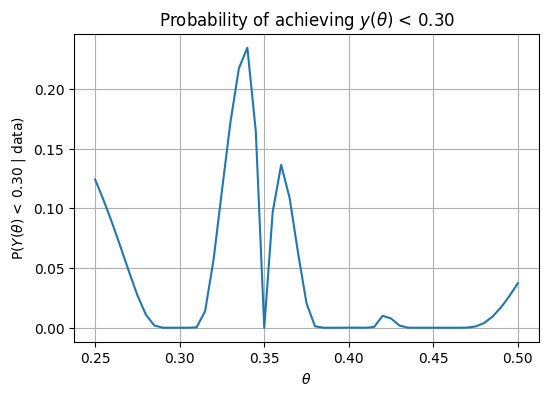

In [3]:
# b) 
from scipy.stats import norm

# Compute pointwise probabilities P(Y < 0.30)
probs = norm.cdf((0.3 - mu_post) / std_post)

# Plot
plt.figure(figsize=(6,4))
plt.plot(theta_grid, probs)
plt.xlabel(r'$\theta$')
plt.ylabel(r'P$(Y(\theta)$ < 0.30 | data)')
plt.title(r'Probability of achieving $y(\theta)$ < 0.30')
plt.grid(True)
plt.show()

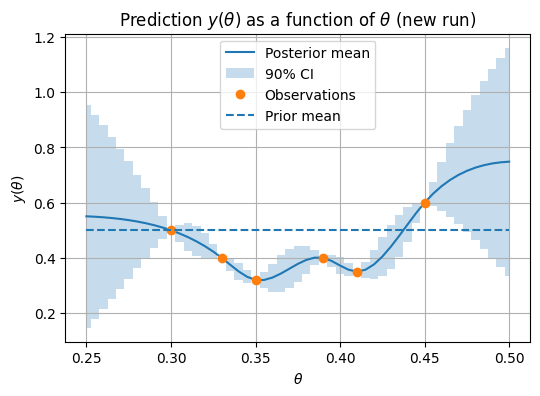

In [4]:
# c)

# copy paste from a) but with appended values 
# observations
theta_obs = np.array([0.30,0.33,0.35,0.39,0.41,0.45])
y_obs     = np.array([0.50,0.40,0.32,0.40,0.35,0.60])

# prior
mu = 0.5 # mean  
var = 0.25 # variance

def cov(t1, t2):
    d = np.abs(t1[:,None] - t2[None,:])
    return var * (1 + 15*d) * np.exp(-15*d)

# grid 
theta_grid = np.arange(0.25, 0.5001, 0.005) # to include endpoint

covAA = cov(theta_grid, theta_grid)
covAB = cov(theta_grid, theta_obs)
covBB = cov(theta_obs, theta_obs)

jitter = 1e-10 # for numerical stability
L = cho_factor(covBB + jitter*np.eye(len(theta_obs)), lower=True)

# posterior mean
temp = cho_solve(L, y_obs - mu)
mu_post = mu + covAB.dot(temp)

# posterior covariance
temp = cho_solve(L, covAB.T)
cov_post = covAA - covAB.dot(temp)
var_post = np.clip(np.diag(cov_post), 0, None)

# 90% CI 
std_post = np.sqrt(var_post) # posterior stdeviation
z90 = 1.6448536269514722 # two-sided 90% quantile 
lower90 = mu_post - z90 * std_post
upper90 = mu_post + z90 * std_post

# Plot
plt.figure(figsize=(6,4))#
plt.title(r'Prediction $y(\theta)$ as a function of $\theta$ (new run)')
plt.plot(theta_grid, mu_post, label='Posterior mean')
plt.fill_between(theta_grid, lower90, upper90, alpha=0.25, step='mid', label=f'90% CI')
plt.plot(theta_obs, y_obs, 'o', label='Observations')
plt.hlines(mu, theta_grid[0], theta_grid[-1], linestyles='--', label='Prior mean')
plt.xlabel(r'$\theta$') 
plt.ylabel(r'$y(\theta)$')
plt.legend()
plt.grid()
plt.show()


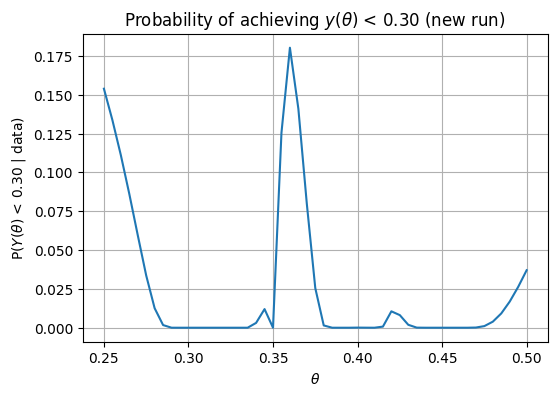

In [5]:
# b) 
from scipy.stats import norm

# Compute pointwise probabilities P(Y < 0.30)
probs = norm.cdf((0.3 - mu_post) / std_post)

# Plot
plt.figure(figsize=(6,4))
plt.plot(theta_grid, probs)
plt.xlabel(r'$\theta$')
plt.ylabel(r'P$(Y(\theta)$ < 0.30 | data)')
plt.title(r'Probability of achieving $y(\theta)$ < 0.30 (new run)')
plt.grid()
plt.show()

In [6]:
best_idx = np.argmax(probs)
best_theta = theta_grid[best_idx]
best_prob = probs[best_idx]
print("Recommended next theta:", best_theta)
print("Max probability of Y<0.30 at this theta:", best_prob)

Recommended next theta: 0.3600000000000001
Max probability of Y<0.30 at this theta: 0.18021433217333177
